# Olist Delivery Performance and Commercial Impact: Python Analysis

Analysis of 96,470 delivered orders from the Olist Brazilian e-commerce dataset, using the SQL Server tables built in the SQL scripts.

| Metric | Definition |
|---|---|
| Late order | Delivered date is later than the estimated date |
| Delay (days) | Delivered date minus estimated date (positive means late) |
| Low review | Review score of 1 or 2 |
| Order GMV | Item price only, summed to order level (freight is kept separately) |
| GMV exposure | GMV in late orders. It is exposure, not lost revenue |
| Eligible seller | Seller with 20 or more orders |


## Setup

In [1]:
import urllib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sqlalchemy import create_engine
from statsmodels.stats.proportion import proportions_ztest
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- connection settings (edit only this block) ----
SERVER_NAME = "localhost\\SQLEXPRESS"
DATABASE_NAME = "OlistDB"
MIN_SELLER_ORDERS = 20     # eligible seller rule, same as SQL and Power BI

params = urllib.parse.quote_plus(
    f"DRIVER={{ODBC Driver 17 for SQL Server}};"
    f"SERVER={SERVER_NAME};"
    f"DATABASE={DATABASE_NAME};"
    f"Trusted_Connection=yes;"
)
engine = create_engine(f"mssql+pyodbc:///?odbc_connect={params}")

# ---- one colour meaning everywhere: late = red, on-time = blue, context = grey ----
LATE, ONTIME, GREY = "#d6294a", "#2563eb", "#94a3b8"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left",
})

fill_values = {}   # key numbers collected along the way


def run_sql(query):
    """Run a query and return a DataFrame with lower-case column names."""
    df = pd.read_sql(query, con=engine)
    df.columns = df.columns.str.lower()
    return df


def fmt_p(p):
    """Readable p-value (tiny values underflow to 0)."""
    return "< 1e-300" if p < 1e-300 else f"{p:.3e}"

In [2]:
df_orders = run_sql("SELECT * FROM silver_orders")
df_sellers = run_sql("SELECT * FROM silver_order_seller")
df_fact = run_sql("""
    SELECT order_id, is_late, review_score, total_freight, total_gmv, category
    FROM gold_fact_orders
""")

print(f"silver_orders:        {len(df_orders):,} rows")
print(f"silver_order_seller:  {len(df_sellers):,} rows")
print(f"gold_fact_orders:     {len(df_fact):,} rows")
display(df_orders.head())

silver_orders:        96,470 rows
silver_order_seller:  97,811 rows
gold_fact_orders:     96,470 rows


,order_id,customer_id,customer_state,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,approval_days,seller_processing_days,carrier_transit_days,total_delivery_days,promise_days,deliv_delay_days,is_late,total_items,total_gmv,total_freight,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,SP,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,0.0,2.0,6.0,8,16,-8,0,1,29.99,8.72,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,BA,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2.0,0.0,12.0,14,20,-6,0,1,118.70,22.76,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,GO,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,0.0,0.0,9.0,9,27,-18,0,1,159.90,19.22,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,RN,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,0.0,4.0,10.0,14,27,-13,0,1,45.00,27.20,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,SP,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,0.0,1.0,2.0,3,13,-10,0,1,19.90,8.72,5.0


### Check totals against SQL
The notebook stops if the totals do not match the SQL results.

In [3]:
checks = {
    "delivered orders = 96,470": len(df_orders) == 96470,
    "late orders = 6,534": int(df_orders["is_late"].sum()) == 6534,
    "order-seller late rows = 6,547": int(df_sellers["is_late"].sum()) == 6547,
    "total GMV = 13,220,248.93": abs(df_orders["total_gmv"].sum() - 13220248.93) < 1,
    "gold rows = silver rows": len(df_fact) == len(df_orders),
    "is_late agrees with delay days": bool(
        ((df_orders["deliv_delay_days"] > 0).astype(int) == df_orders["is_late"]).all()
    ),
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values()), "Reconciliation failed: fix the SQL layer before going on."

PASS  delivered orders = 96,470
PASS  late orders = 6,534
PASS  order-seller late rows = 6,547
PASS  total GMV = 13,220,248.93
PASS  gold rows = silver rows
PASS  is_late agrees with delay days


## 1. Exploratory analysis

### Missing values

In [4]:
stage_cols = ["approval_days", "seller_processing_days", "carrier_transit_days", "deliv_delay_days"]
completeness = pd.DataFrame({
    "missing": df_orders[stage_cols + ["review_score"]].isna().sum(),
    "missing_pct": (df_orders[stage_cols + ["review_score"]].isna().mean() * 100).round(2),
})
display(completeness)
display(df_orders[stage_cols].describe().round(2))

,missing,missing_pct
approval_days,14,0.01
seller_processing_days,15,0.02
carrier_transit_days,1,0.00
deliv_delay_days,0,0.00
review_score,646,0.67


,approval_days,seller_processing_days,carrier_transit_days,deliv_delay_days
count,96456.00,96455.00,96469.00,96470.00
mean,0.51,2.70,9.28,-11.88
std,0.96,3.56,8.78,10.18
min,0.00,-171.00,-16.00,-147.00
25%,0.00,1.00,4.00,-17.00
50%,0.00,2.00,7.00,-12.00
75%,1.00,3.00,12.00,-7.00
max,31.00,126.00,205.00,188.00


Missing review scores stay missing. Review rates divide by reviewed orders only.

### Delivery delay against the promised date

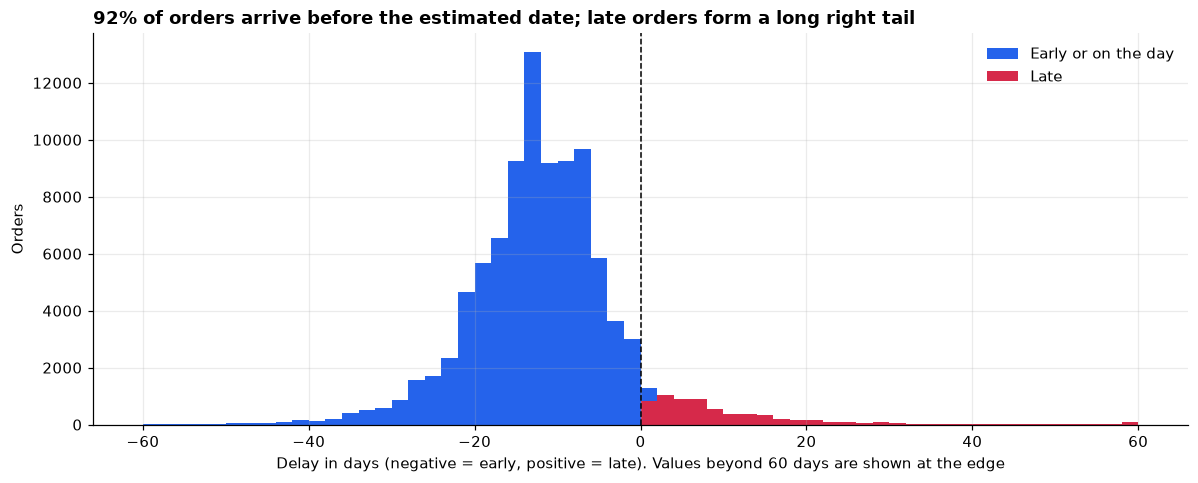

In [5]:
delay = df_orders["deliv_delay_days"]
share_early = (delay < 0).mean()
bins = np.arange(-60, 62, 2)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(delay[delay <= 0].clip(-60, 60), bins=bins, color=ONTIME, label="Early or on the day")
ax.hist(delay[delay > 0].clip(-60, 60), bins=bins, color=LATE, label="Late")
ax.axvline(0, color="black", lw=1, ls="--")
ax.set_title(f"{share_early:.0%} of orders arrive before the estimated date; late orders form a long right tail")
ax.set_xlabel("Delay in days (negative = early, positive = late). Values beyond 60 days are shown at the edge")
ax.set_ylabel("Orders")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Stage times, late vs on-time

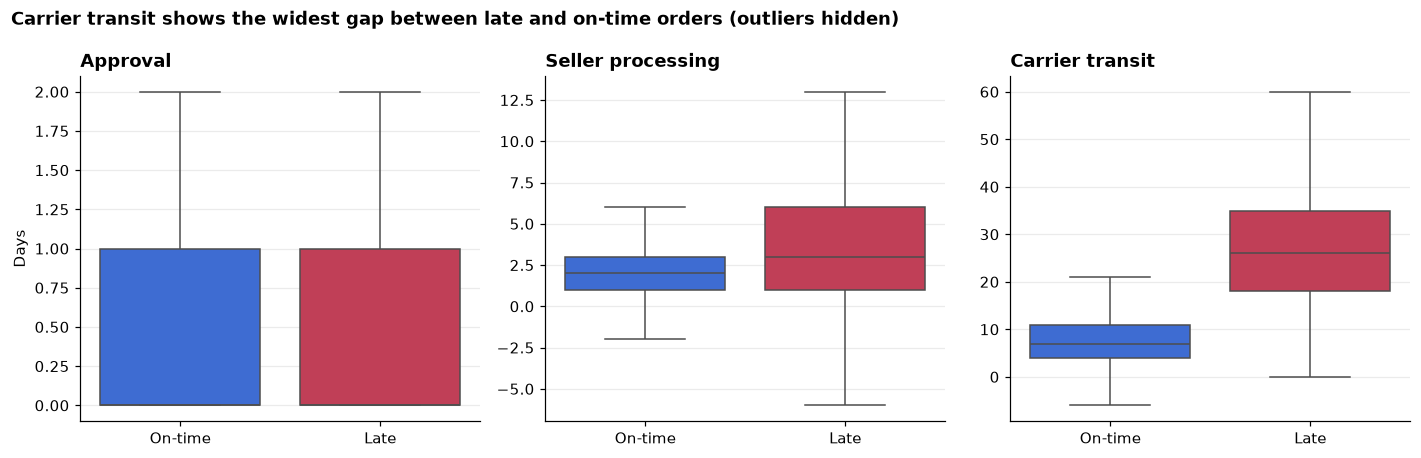

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
titles = {"approval_days": "Approval", "seller_processing_days": "Seller processing", "carrier_transit_days": "Carrier transit"}
plot_df = df_orders.assign(group=np.where(df_orders["is_late"] == 1, "Late", "On-time"))
for ax, (col, title) in zip(axes, titles.items()):
    sns.boxplot(data=plot_df, x="group", y=col, order=["On-time", "Late"], ax=ax, showfliers=False,
                palette={"On-time": ONTIME, "Late": LATE})
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Days" if col == "approval_days" else "")
fig.suptitle("Carrier transit shows the widest gap between late and on-time orders (outliers hidden)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### Outliers

In [7]:
pct = [0.5, 0.9, 0.95, 0.99, 0.999]
outlier_table = df_orders[["deliv_delay_days", "carrier_transit_days", "seller_processing_days"]].quantile(pct).round(1)
outlier_table.index = [f"P{p*100:g}" for p in pct]
display(outlier_table)

q1, q3 = delay.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
n_extreme = int((delay > upper_fence).sum())
print(f"Delay IQR upper fence: {upper_fence:.1f} days. Orders beyond it: {n_extreme:,} ({n_extreme/len(df_orders):.1%})")
print(f"Longest delay: {delay.max():.0f} days. Longest carrier transit: {df_orders['carrier_transit_days'].max():.0f} days.")

,deliv_delay_days,carrier_transit_days,seller_processing_days
P50,-12.0,7.0,2.0
P90,-2.0,19.0,6.0
P95,3.0,24.0,8.0
P99,18.0,41.0,17.0
P99.9,55.0,77.0,36.0


Delay IQR upper fence: 8.0 days. Orders beyond it: 2,526 (2.6%)
Longest delay: 188 days. Longest carrier transit: 205 days.


I kept all extreme values. They are real delivered orders, and the severe delays are what the business wants to find. I report medians and percentiles next to averages.

### Monthly trend

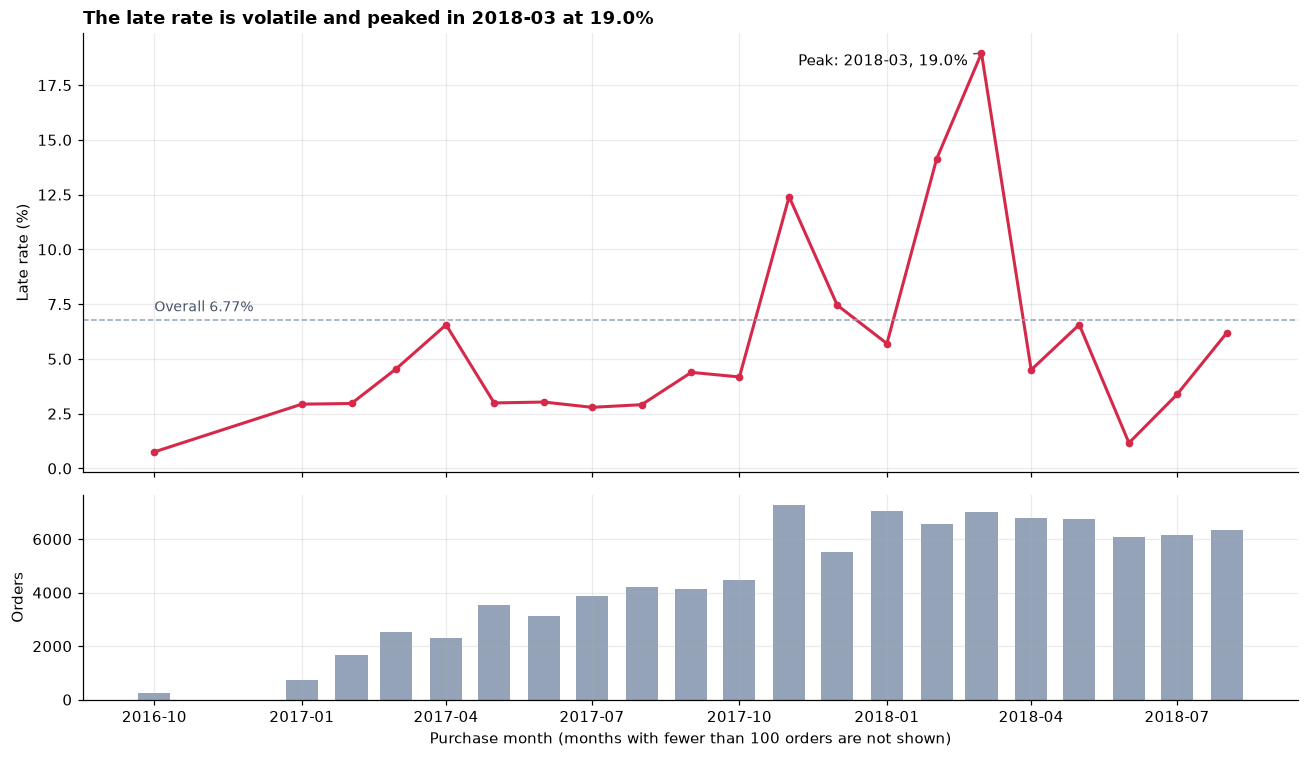

In [8]:
df_orders["order_month"] = pd.to_datetime(df_orders["order_purchase_timestamp"]).dt.to_period("M")
monthly = (df_orders.groupby("order_month")
           .agg(orders=("order_id", "count"), late_rate=("is_late", "mean"))
           .reset_index())
monthly["late_rate"] *= 100
monthly_plot = monthly[monthly["orders"] >= 100].copy()     # drop 2016 and the last tiny months
monthly_plot["month"] = monthly_plot["order_month"].dt.to_timestamp()

peak = monthly_plot.loc[monthly_plot["late_rate"].idxmax()]
overall_rate = df_orders["is_late"].mean() * 100
fill_values["S1 peak month"] = f"{peak['order_month']} at {peak['late_rate']:.2f}%"

def month_rate(m):
    row = monthly[monthly["order_month"] == pd.Period(m)]
    return None if row.empty else float(row["late_rate"].iloc[0])

fill_values["S1 Oct 2017 late rate"] = round(month_rate("2017-10"), 2)
fill_values["S1 Nov 2017 late rate"] = round(month_rate("2017-11"), 2)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.4]})
ax1.plot(monthly_plot["month"], monthly_plot["late_rate"], color=LATE, lw=2, marker="o", ms=4)
ax1.axhline(overall_rate, color=GREY, ls="--", lw=1)
ax1.text(monthly_plot["month"].iloc[0], overall_rate + 0.4, f"Overall {overall_rate:.2f}%", color="#475569", fontsize=9)
ax1.annotate(f"Peak: {peak['order_month']}, {peak['late_rate']:.1f}%", xy=(peak["month"], peak["late_rate"]),
             xytext=(-120, -8), textcoords="offset points", arrowprops=dict(arrowstyle="-", color="#475569"))
ax1.set_ylabel("Late rate (%)")
ax1.set_title(f"The late rate is volatile and peaked in {peak['order_month']} at {peak['late_rate']:.1f}%")
ax2.bar(monthly_plot["month"], monthly_plot["orders"], width=20, color=GREY)
ax2.set_ylabel("Orders")
ax2.set_xlabel("Purchase month (months with fewer than 100 orders are not shown)")
plt.tight_layout()
plt.show()

### Sensitivity to the promised date
The estimated date is treated as the promise. I tested a grace period of 1, 2 and 3 days.

In [9]:
reviewed = df_orders["review_score"].notna()
low = df_orders["review_score"] <= 2
rows = []
for grace in [0, 1, 2, 3]:
    late = df_orders["deliv_delay_days"] > grace
    rows.append({
        "grace_days": grace,
        "late_orders": int(late.sum()),
        "late_rate_pct": round(late.mean() * 100, 2),
        "low_review_pct_late": round(low[late & reviewed].mean() * 100, 2),
        "low_review_pct_not_late": round(low[~late & reviewed].mean() * 100, 2),
    })
sensitivity = pd.DataFrame(rows)
display(sensitivity)

,grace_days,late_orders,late_rate_pct,low_review_pct_late,low_review_pct_not_late
0,0,6534,6.77,62.42,9.28
1,1,5709,5.92,68.73,9.37
2,2,5164,5.35,72.40,9.52
3,3,4664,4.83,74.81,9.74


The late rate falls with a grace period, but late orders still have a much higher low-review rate at every setting. The conclusion does not change.

## 2. Business questions
The same queries are in `05_analysis_final.sql`.

### Q1. Where do delays occur?

In [10]:
q1a = """
SELECT
    is_late,
    COUNT(*)                                              AS orders,
    ROUND(AVG(CAST(approval_days AS FLOAT)), 2)           AS avg_approval_days,
    ROUND(AVG(CAST(seller_processing_days AS FLOAT)), 2)  AS avg_seller_days,
    ROUND(AVG(CAST(carrier_transit_days AS FLOAT)), 2)    AS avg_carrier_days
FROM silver_orders
GROUP BY is_late
ORDER BY is_late;
"""
df_q1a = run_sql(q1a)
display(df_q1a)

q1b = """
SELECT
    is_late,
    COUNT(*) AS orders,
    ROUND(AVG(CAST(deliv_delay_days AS FLOAT)), 2) AS avg_delay_vs_promise_days,
    ROUND(100.0 * SUM(CASE WHEN deliv_delay_days < 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_delivered_before_promise
FROM silver_orders
GROUP BY is_late
ORDER BY is_late;
"""
df_q1b = run_sql(q1b)
display(df_q1b)

,is_late,orders,avg_approval_days,avg_seller_days,avg_carrier_days
0,0,89936,0.51,2.50,7.93
1,1,6534,0.61,5.43,27.87


,is_late,orders,avg_delay_vs_promise_days,pct_delivered_before_promise
0,0,89936,-13.51,98.56
1,1,6534,10.62,0.00


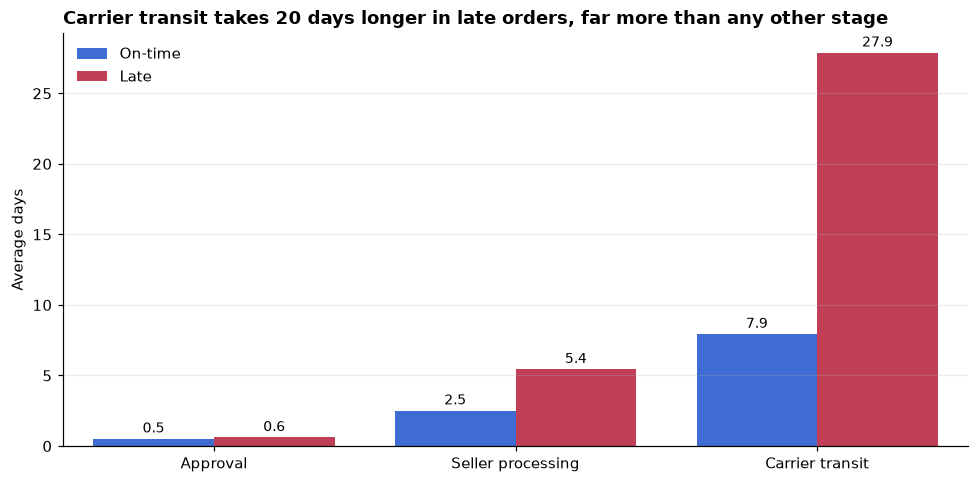

In [11]:
stage = df_q1a.melt(id_vars="is_late", value_vars=["avg_approval_days", "avg_seller_days", "avg_carrier_days"],
                    var_name="stage", value_name="days")
stage["stage"] = stage["stage"].map({"avg_approval_days": "Approval", "avg_seller_days": "Seller processing",
                                     "avg_carrier_days": "Carrier transit"})
stage["group"] = stage["is_late"].map({0: "On-time", 1: "Late"})
gap = (df_q1a.loc[df_q1a.is_late == 1, "avg_carrier_days"].iloc[0] - df_q1a.loc[df_q1a.is_late == 0, "avg_carrier_days"].iloc[0])

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=stage, x="stage", y="days", hue="group", hue_order=["On-time", "Late"],
            palette={"On-time": ONTIME, "Late": LATE}, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", padding=2, fontsize=9)
ax.set_title(f"Carrier transit takes {gap:.0f} days longer in late orders, far more than any other stage")
ax.set_xlabel("")
ax.set_ylabel("Average days")
ax.legend(title="", frameon=False)
plt.tight_layout()
plt.show()

Carrier transit differs most: 27.87 days for late orders against 7.93 for on-time orders. Seller processing differs by about 3 days (5.43 against 2.50). Approval is almost the same. On-time orders arrive 13.5 days early on average, and late orders arrive 10.6 days late.

**Action:** review carrier transit first.

### Q2. How are delays associated with reviews?

In [12]:
q2 = """
SELECT
    CASE WHEN deliv_delay_days <= 0  THEN '1. Early/On-time'
         WHEN deliv_delay_days <= 5  THEN '2. 1-5 days late'
         WHEN deliv_delay_days <= 15 THEN '3. 6-15 days late'
         ELSE                             '4. 16+ days late'
    END AS delay_band,
    COUNT(*) AS orders,
    ROUND(AVG(CAST(review_score AS FLOAT)), 2) AS avg_review_score,
    ROUND(100.0 * SUM(CASE WHEN review_score <= 2 THEN 1 ELSE 0 END) / COUNT(review_score), 2) AS low_review_pct
FROM silver_orders
GROUP BY
    CASE WHEN deliv_delay_days <= 0  THEN '1. Early/On-time'
         WHEN deliv_delay_days <= 5  THEN '2. 1-5 days late'
         WHEN deliv_delay_days <= 15 THEN '3. 6-15 days late'
         ELSE                             '4. 16+ days late'
    END
ORDER BY delay_band;
"""
df_q2 = run_sql(q2)
display(df_q2)

,delay_band,orders,avg_review_score,low_review_pct
0,1. Early/On-time,89936,4.29,9.28
1,2. 1-5 days late,2770,2.99,41.15
2,3. 6-15 days late,2539,1.74,78.22
3,4. 16+ days late,1225,1.73,78.31


The low-review rate rises from 9.28% (on time) to 41.15% at 1 to 5 days late, and to about 78% beyond 5 days.

**Action:** contact customers once an order passes its estimated date.

### Q3. Which sellers need attention?
Only sellers with 20 or more orders. An order with two sellers counts once for each.

In [13]:
q3a = f"""
;WITH lateSeller AS (
    SELECT seller_id,
           COUNT(*)                                    AS total_orders,
           SUM(is_late)                                AS total_late_orders,
           ROUND(AVG(CAST(is_late AS FLOAT)) * 100, 2) AS late_rate_pct,
           ROUND(SUM(seller_gmv), 2)                   AS total_gmv
    FROM silver_order_seller
    GROUP BY seller_id
    HAVING COUNT(*) >= {MIN_SELLER_ORDERS}
)
SELECT seller_id, total_orders, total_late_orders, late_rate_pct, total_gmv,
       SUM(total_late_orders) OVER (ORDER BY total_late_orders DESC, seller_id
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS running_total,
       ROUND(100.0 * SUM(total_late_orders) OVER (ORDER BY total_late_orders DESC, seller_id
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
            / SUM(total_late_orders) OVER (), 2)              AS cumulative_pct,
       ROW_NUMBER() OVER (ORDER BY total_late_orders DESC, seller_id) AS seller_rank,
       COUNT(*) OVER ()                                       AS eligible_sellers
FROM lateSeller
ORDER BY total_late_orders DESC, seller_id;
"""
df_pareto = run_sql(q3a)
print(f"Eligible sellers: {len(df_pareto):,}")
display(df_pareto.head(20))

Eligible sellers: 804


,seller_id,total_orders,total_late_orders,late_rate_pct,total_gmv,running_total,cumulative_pct,seller_rank,eligible_sellers
0,4a3ca9315b744ce9f8e9374361493884,1772,172,9.71,196882.12,172,2.99,1,804
1,1f50f920176fa81dab994f9023523100,1399,124,8.86,106655.71,296,5.15,2,804
2,4869f7a5dfa277a7dca6462dcf3b52b2,1124,118,10.50,226987.93,414,7.20,3,804
3,6560211a19b47992c3666cc44a7e94c0,1819,96,5.28,120702.83,510,8.87,4,804
4,ea8482cd71df3c1969d7b9473ff13abc,1132,96,8.48,36696.76,606,10.54,5,804
5,7c67e1448b00f6e969d365cea6b010ab,973,89,9.15,186570.05,695,12.08,6,804
6,cc419e0650a3c5ba77189a1882b7556a,1651,87,5.27,101090.96,782,13.60,7,804
7,da8622b14eb17ae2831f4ac5b9dab84a,1311,87,6.64,159816.87,869,15.11,8,804
8,8b321bb669392f5163d04c59e235e066,930,81,8.71,17262.94,950,16.52,9,804
9,955fee9216a65b617aa5c0531780ce60,1261,77,6.11,131836.71,1027,17.85,10,804


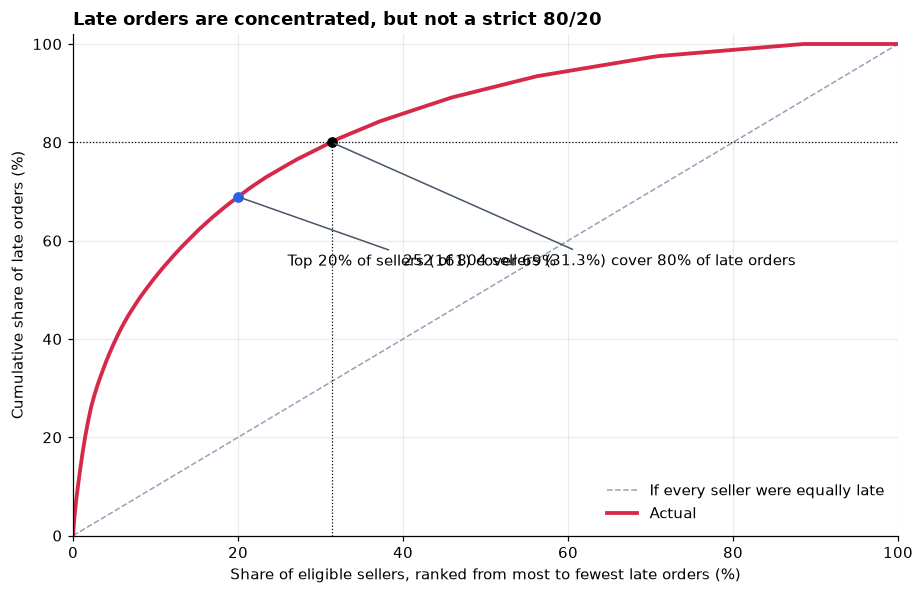

In [14]:
n_sellers = len(df_pareto)
total_late = df_pareto["total_late_orders"].sum()
# a seller is counted if the running total BEFORE it is still below 80% (same rule as SQL and DAX)
n80 = int((df_pareto["running_total"] - df_pareto["total_late_orders"] < 0.8 * total_late).sum())
n20 = int(np.ceil(0.2 * n_sellers))
share_top20 = df_pareto.loc[n20 - 1, "cumulative_pct"]

x = np.r_[0, df_pareto["seller_rank"].to_numpy() / n_sellers * 100]
y = np.r_[0, df_pareto["cumulative_pct"].to_numpy()]

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot([0, 100], [0, 100], color=GREY, ls="--", lw=1, label="If every seller were equally late")
ax.plot(x, y, color=LATE, lw=2.5, label="Actual")
ax.legend(loc="lower right", frameon=False)
ax.axhline(80, color="black", lw=0.8, ls=":")
ax.plot([n80 / n_sellers * 100] * 2, [0, 80], color="black", lw=0.8, ls=":")
ax.scatter([n80 / n_sellers * 100], [80], color="black", zorder=3)
ax.annotate(f"{n80} of {n_sellers} sellers ({n80/n_sellers:.1%}) cover 80% of late orders",
            xy=(n80 / n_sellers * 100, 80), xytext=(40, 55), arrowprops=dict(arrowstyle="-", color="#475569"))
ax.scatter([20], [share_top20], color=ONTIME, zorder=3)
ax.annotate(f"Top 20% of sellers ({n20}) cover {share_top20:.0f}%", xy=(20, share_top20), xytext=(26, share_top20 - 14),
            arrowprops=dict(arrowstyle="-", color="#475569"))
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.set_xlabel("Share of eligible sellers, ranked from most to fewest late orders (%)")
ax.set_ylabel("Cumulative share of late orders (%)")
ax.set_title("Late orders are concentrated, but not a strict 80/20")
plt.tight_layout()
plt.show()

fill_values["Q3 sellers for 80%"] = f"{n80} of {n_sellers} ({n80/n_sellers:.1%})"
fill_values["Q3 top 20% of sellers cover"] = f"{share_top20:.1f}% of late orders (top {n20} sellers)"

In [15]:
q3b = f"""
;WITH s AS (
    SELECT seller_id, COUNT(*) AS orders, SUM(is_late) AS late
    FROM silver_order_seller GROUP BY seller_id HAVING COUNT(*) >= {MIN_SELLER_ORDERS}
),
r AS (
    SELECT seller_id, orders, late,
           SUM(late) OVER (ORDER BY late DESC, seller_id ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS running,
           SUM(late) OVER () AS total_late
    FROM s
),
g AS (
    SELECT *, CASE WHEN running - late < 0.8 * total_late
                   THEN '1. Top group (80% of late orders)' ELSE '2. Other eligible sellers' END AS grp
    FROM r
)
SELECT grp, COUNT(*) AS sellers, SUM(orders) AS orders,
       ROUND(100.0 * SUM(orders) / SUM(SUM(orders)) OVER (), 2) AS order_share_pct,
       SUM(late) AS late_orders,
       ROUND(100.0 * SUM(late) / SUM(orders), 2) AS late_rate_pct
FROM g GROUP BY grp ORDER BY grp;
"""
df_q3b = run_sql(q3b)
display(df_q3b)

q3c = f"""
;WITH s AS (SELECT seller_id, COUNT(*) AS orders, SUM(is_late) AS late FROM silver_order_seller GROUP BY seller_id)
SELECT SUM(CASE WHEN orders >= {MIN_SELLER_ORDERS} THEN late ELSE 0 END) AS late_in_eligible_sellers,
       SUM(late) AS late_in_all_sellers,
       SUM(CASE WHEN orders >= {MIN_SELLER_ORDERS} THEN 1 ELSE 0 END) AS eligible_sellers,
       COUNT(*) AS all_sellers
FROM s;
"""
df_q3c = run_sql(q3c)
display(df_q3c)

,grp,sellers,orders,order_share_pct,late_orders,late_rate_pct
0,1. Top group (80% of late orders),252,58474,68.07,4605,7.88
1,2. Other eligible sellers,552,27432,31.93,1147,4.18


,late_in_eligible_sellers,late_in_all_sellers,eligible_sellers,all_sellers
0,5752,6547,804,2970


252 of 804 eligible sellers (31.3%) account for 80% of late orders, so it is closer to 80/31 than 80/20. This top group has a late rate of 7.88%, against 4.18% for the other 552 sellers. Their late rate may partly reflect region, since carrier transit is the main delay.

**Action:** coach the top group first, starting with the highest late rate.

### Q4. What is the GMV exposure?

In [16]:
q4a = """
SELECT
    SUM(total_gmv) AS total_company_gmv,
    SUM(CASE WHEN is_late = 1 THEN total_gmv ELSE 0 END) AS late_gmv,
    SUM(CASE WHEN is_late = 1 AND review_score <= 2 THEN total_gmv ELSE 0 END) AS late_low_rated_gmv
FROM silver_orders;
"""
df_q4a = run_sql(q4a)
total_gmv = float(df_q4a["total_company_gmv"].iloc[0])
late_gmv = float(df_q4a["late_gmv"].iloc[0])
late_low_gmv = float(df_q4a["late_low_rated_gmv"].iloc[0])

exposure = pd.DataFrame({
    "measure": ["Total GMV", "GMV in late orders", "GMV in late, low-rated orders"],
    "gmv": [total_gmv, late_gmv, late_low_gmv],
    "share_of_total_pct": [100.0, late_gmv / total_gmv * 100, late_low_gmv / total_gmv * 100],
    "share_of_late_gmv_pct": [None, 100.0, late_low_gmv / late_gmv * 100],
}).round(2)
display(exposure)

,measure,gmv,share_of_total_pct,share_of_late_gmv_pct
0,Total GMV,13220248.93,100.00,NaN
1,GMV in late orders,985924.34,7.46,100.00
2,"GMV in late, low-rated orders",619012.41,4.68,62.78


Late orders carry 7.46% of GMV (985,924 of 13,220,249). Of that, 619,012 is in late orders with a 1 or 2 star review. This is exposure, not lost revenue.

### S1. Late rate by month

In [17]:
s1 = """
SELECT FORMAT(order_purchase_timestamp, 'yyyy-MM') AS order_month,
       COUNT(*) AS total_orders,
       ROUND(AVG(CAST(is_late AS FLOAT)) * 100, 2) AS late_rate_pct
FROM silver_orders
GROUP BY FORMAT(order_purchase_timestamp, 'yyyy-MM')
ORDER BY order_month;
"""
df_s1 = run_sql(s1)
display(df_s1)

,order_month,total_orders,late_rate_pct
0,2016-09,1,100.00
1,2016-10,265,0.75
2,2016-12,1,0.00
3,2017-01,750,2.93
4,2017-02,1653,2.96
5,2017-03,2546,4.56
6,2017-04,2303,6.56
7,2017-05,3545,2.99
8,2017-06,3135,3.03
9,2017-07,3872,2.79


The late rate stayed between 2.79% and 6.56% from Jan to Aug 2017, then rose when order volume surged. The peak was March 2018 at 18.96%.

### S2. Worst states and categories

,customer_state,total_orders,late_rate_pct,low_review_pct
0,MA,717,17.43,19.94
1,CE,1279,13.76,17.12
2,BA,3256,12.16,17.03
3,RJ,12350,12.11,18.34
4,PA,946,11.21,17.90
5,ES,1995,10.73,13.81
6,PB,517,10.44,14.84
7,MS,701,9.70,13.30
8,PE,1593,9.60,14.82
9,SC,3546,8.21,13.02


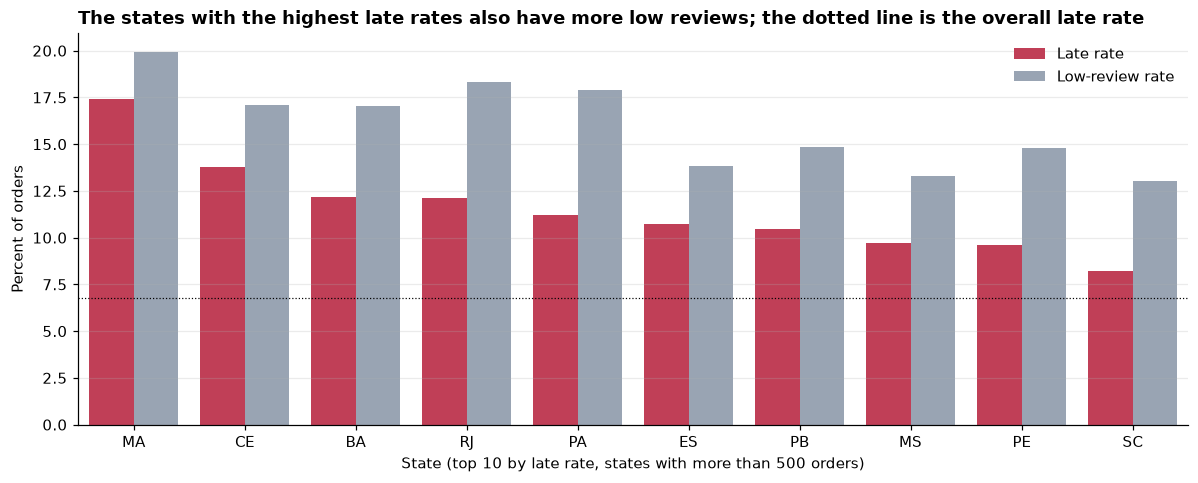

In [18]:
s2a = """
SELECT customer_state,
       COUNT(*) AS total_orders,
       ROUND(AVG(CAST(is_late AS FLOAT)) * 100, 2) AS late_rate_pct,
       ROUND(100.0 * SUM(CASE WHEN review_score <= 2 THEN 1 ELSE 0 END) / COUNT(review_score), 2) AS low_review_pct
FROM silver_orders
GROUP BY customer_state
HAVING COUNT(*) > 500
ORDER BY late_rate_pct DESC;
"""
df_s2a = run_sql(s2a)
sp = df_s2a[df_s2a["customer_state"] == "SP"]
if not sp.empty:
    fill_values["S2 Sao Paulo (SP)"] = (f"{int(sp['total_orders'].iloc[0]):,} orders, late rate {sp['late_rate_pct'].iloc[0]}%, "
                                        f"low-review {sp['low_review_pct'].iloc[0]}%")
display(df_s2a)

top10 = df_s2a.head(10).melt(id_vars="customer_state", value_vars=["late_rate_pct", "low_review_pct"],
                            var_name="metric", value_name="pct")
top10["metric"] = top10["metric"].map({"late_rate_pct": "Late rate", "low_review_pct": "Low-review rate"})
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=top10, x="customer_state", y="pct", hue="metric",
            palette={"Late rate": LATE, "Low-review rate": GREY}, ax=ax)
ax.axhline(df_orders["is_late"].mean() * 100, color="black", lw=0.8, ls=":")
ax.set_title("The states with the highest late rates also have more low reviews; the dotted line is the overall late rate")
ax.set_xlabel("State (top 10 by late rate, states with more than 500 orders)")
ax.set_ylabel("Percent of orders")
ax.legend(title="", frameon=False)
plt.tight_layout()
plt.show()

,category,total_orders,late_rate_pct,low_review_pct
0,BABY,2759,8.12,13.81
1,OFFICE_FURNITURE,1252,8.07,21.90
2,ELECTRONICS,2502,7.67,13.05
3,MUSICAL_INSTRUMENTS,607,7.58,11.48
4,HEALTH_BEAUTY,8613,7.54,11.32
5,BED_BATH_TABLE,9174,7.47,15.87
6,CONSTRUCTION_TOOLS_CONSTRUCTION,724,7.46,12.66
7,WATCHES_GIFTS,5476,7.41,13.65
8,AUTO,3792,7.33,12.82
9,FURNITURE_DECOR,6189,7.24,14.91


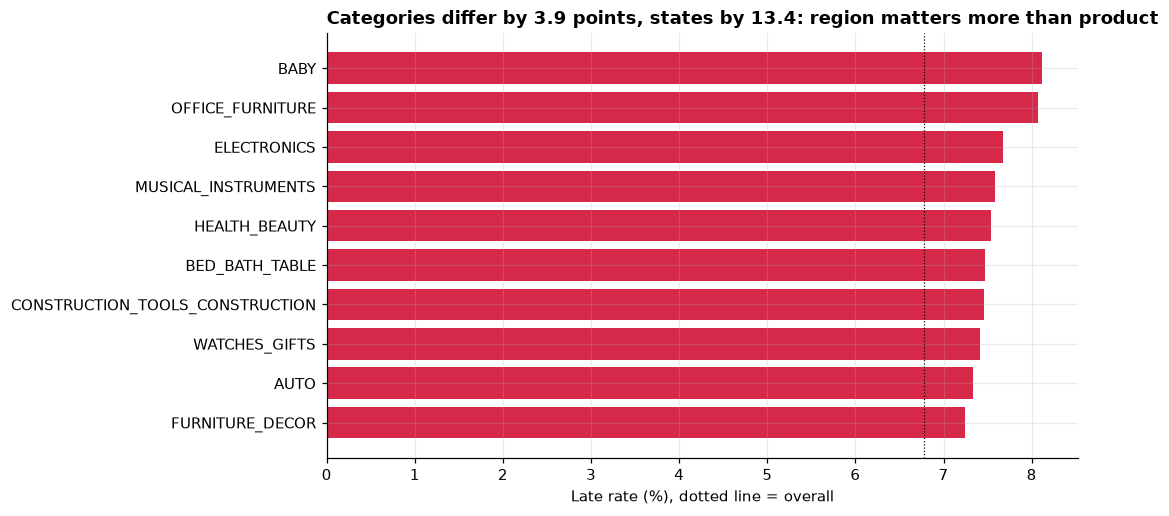

In [19]:
s2b = """
SELECT category,
       COUNT(*) AS total_orders,
       ROUND(AVG(CAST(is_late AS FLOAT)) * 100, 2) AS late_rate_pct,
       ROUND(100.0 * SUM(CASE WHEN review_score <= 2 THEN 1 ELSE 0 END) / COUNT(review_score), 2) AS low_review_pct
FROM gold_fact_orders
GROUP BY category
HAVING COUNT(*) > 500
ORDER BY late_rate_pct DESC;
"""
df_s2b = run_sql(s2b)
display(df_s2b.head(15))

fig, ax = plt.subplots(figsize=(10, 4.8))
t = df_s2b.head(10).iloc[::-1]
ax.barh(t["category"], t["late_rate_pct"], color=LATE)
ax.axvline(df_orders["is_late"].mean() * 100, color="black", lw=0.8, ls=":")
spread_states = df_s2a["late_rate_pct"].max() - df_s2a["late_rate_pct"].min()
spread_cats = df_s2b["late_rate_pct"].max() - df_s2b["late_rate_pct"].min()
ax.set_title(f"Categories differ by {spread_cats:.1f} points, states by {spread_states:.1f}: region matters more than product")
ax.set_xlabel("Late rate (%), dotted line = overall")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

The worst states are MA (17.43%), CE (13.76%), BA (12.16%), RJ (12.11%) and PA (11.21%), against 6.77% overall. Categories are close to each other (BABY 8.12%, OFFICE_FURNITURE 8.07%, ELECTRONICS 7.67%), so region matters more than category.

### S3. How severe are the worst delays?

,median_delay_days,p90_delay_days
0,7.0,22.0


Python check: median 7.00 days, P90 22.00 days (must match the SQL row above)


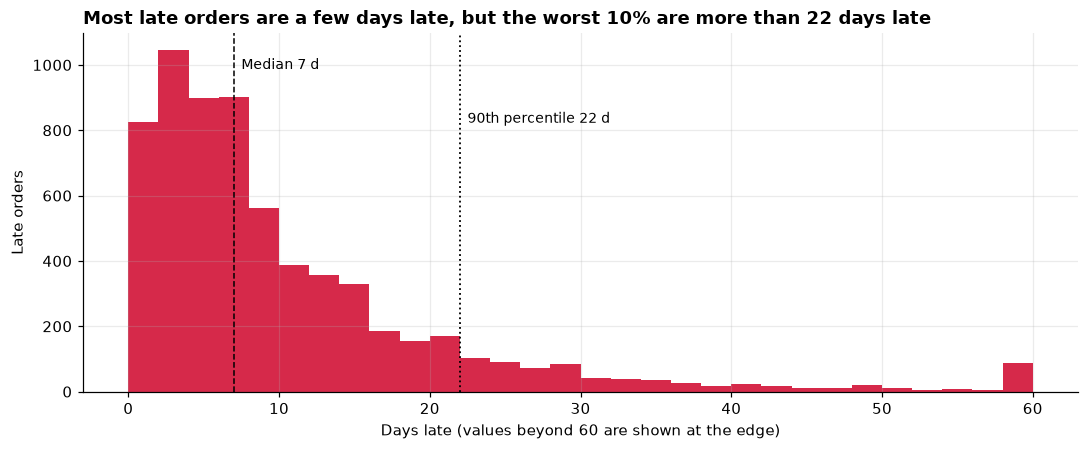

In [20]:
late_delay = df_orders.loc[df_orders["is_late"] == 1, "deliv_delay_days"]
median_delay = late_delay.median()
p90_delay = late_delay.quantile(0.9)
fill_values["S3 median delay (late orders)"] = f"{median_delay:.2f} days"
fill_values["S3 P90 delay (late orders)"] = f"{p90_delay:.2f} days"

s3 = """
SELECT DISTINCT
    CAST(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY deliv_delay_days) OVER () AS DECIMAL(10,2)) AS median_delay_days,
    CAST(PERCENTILE_CONT(0.9) WITHIN GROUP (ORDER BY deliv_delay_days) OVER () AS DECIMAL(10,2)) AS p90_delay_days
FROM silver_orders
WHERE is_late = 1;
"""
df_s3 = run_sql(s3)
display(df_s3)
print(f"Python check: median {median_delay:.2f} days, P90 {p90_delay:.2f} days (must match the SQL row above)")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(late_delay.clip(upper=60), bins=np.arange(0, 62, 2), color=LATE)
ax.axvline(median_delay, color="black", ls="--", lw=1)
ax.axvline(p90_delay, color="black", ls=":", lw=1.2)
ax.text(median_delay + 0.5, ax.get_ylim()[1] * 0.9, f"Median {median_delay:.0f} d", fontsize=9)
ax.text(p90_delay + 0.5, ax.get_ylim()[1] * 0.75, f"90th percentile {p90_delay:.0f} d", fontsize=9)
ax.set_title(f"Most late orders are a few days late, but the worst 10% are more than {p90_delay:.0f} days late")
ax.set_xlabel("Days late (values beyond 60 are shown at the edge)")
ax.set_ylabel("Late orders")
plt.tight_layout()
plt.show()

Among late orders the median delay is 7 days and the 90th percentile is 22 days. In the 16+ days band, 78.31% of reviews are low (1,225 orders).

## 3. Two-proportion test: late vs on-time
This checks whether the gap in low-review rates could be chance. A very small p-value means it is unlikely to be chance. It does not prove that the delay caused the bad review.

In [21]:
def band(days):
    if days <= 0:
        return "1. Early/On-time"
    if days <= 5:
        return "2. 1-5 days late"
    if days <= 15:
        return "3. 6-15 days late"
    return "4. 16+ days late"

df_orders["delay_band"] = df_orders["deliv_delay_days"].apply(band)

band_stats = (df_orders.groupby("delay_band")
              .agg(orders=("order_id", "count"),
                   reviewed=("review_score", "count"),
                   avg_score=("review_score", "mean"),
                   low_reviews=("review_score", lambda s: int((s <= 2).sum())))
              .reset_index())
band_stats["low_review_pct"] = band_stats["low_reviews"] / band_stats["reviewed"] * 100
display(band_stats.round(2))

,delay_band,orders,reviewed,avg_score,low_reviews,low_review_pct
0,1. Early/On-time,89936,89443,4.29,8301,9.28
1,2. 1-5 days late,2770,2722,2.99,1120,41.15
2,3. 6-15 days late,2539,2479,1.74,1939,78.22
3,4. 16+ days late,1225,1180,1.73,924,78.31


In [22]:
def two_prop_test(low_a, n_a, low_b, n_b):
    """Compare group B (late) with group A (on-time). Returns gap in points, 95% CI, z, p."""
    p_a, p_b = low_a / n_a, low_b / n_b
    z, p = proportions_ztest([low_b, low_a], [n_b, n_a])
    se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    gap = (p_b - p_a) * 100
    return gap, gap - 1.96 * se * 100, gap + 1.96 * se * 100, z, p

base = band_stats.iloc[0]
tests = []

# overall: all late orders against on-time orders (all late orders against on-time orders)
is_late_mask = df_orders["is_late"] == 1
rev = df_orders["review_score"].notna()
late_low = int((df_orders.loc[is_late_mask & rev, "review_score"] <= 2).sum())
late_n = int((is_late_mask & rev).sum())
gap, lo, hi, z, p = two_prop_test(int(base["low_reviews"]), int(base["reviewed"]), late_low, late_n)
tests.append({"comparison": "All late vs on-time", "late_low_review_pct": late_low / late_n * 100,
              "on_time_low_review_pct": base["low_review_pct"], "gap_points": gap, "ci_low": lo, "ci_high": hi,
              "z": z, "p_value": fmt_p(p)})
fill_values["Q2 z-test p-value (all late vs on-time)"] = fmt_p(p)

for _, r in band_stats.iloc[1:].iterrows():
    gap, lo, hi, z, p = two_prop_test(int(base["low_reviews"]), int(base["reviewed"]), int(r["low_reviews"]), int(r["reviewed"]))
    tests.append({"comparison": f"{r['delay_band']} vs on-time", "late_low_review_pct": r["low_review_pct"],
                  "on_time_low_review_pct": base["low_review_pct"], "gap_points": gap, "ci_low": lo, "ci_high": hi,
                  "z": z, "p_value": fmt_p(p)})

test_table = pd.DataFrame(tests).round(2)
display(test_table)
print("Four comparisons were run. Even with a strict threshold of 0.05 / 4 = 0.0125 every p-value is far below it.")

,comparison,late_low_review_pct,on_time_low_review_pct,gap_points,ci_low,ci_high,z,p_value
0,All late vs on-time,62.42,9.28,53.14,51.94,54.34,122.67,< 1e-300
1,2. 1-5 days late vs on-time,41.15,9.28,31.87,30.01,33.72,54.06,< 1e-300
2,3. 6-15 days late vs on-time,78.22,9.28,68.94,67.30,70.57,107.61,< 1e-300
3,4. 16+ days late vs on-time,78.31,9.28,69.02,66.66,71.38,77.90,< 1e-300


Four comparisons were run. Even with a strict threshold of 0.05 / 4 = 0.0125 every p-value is far below it.


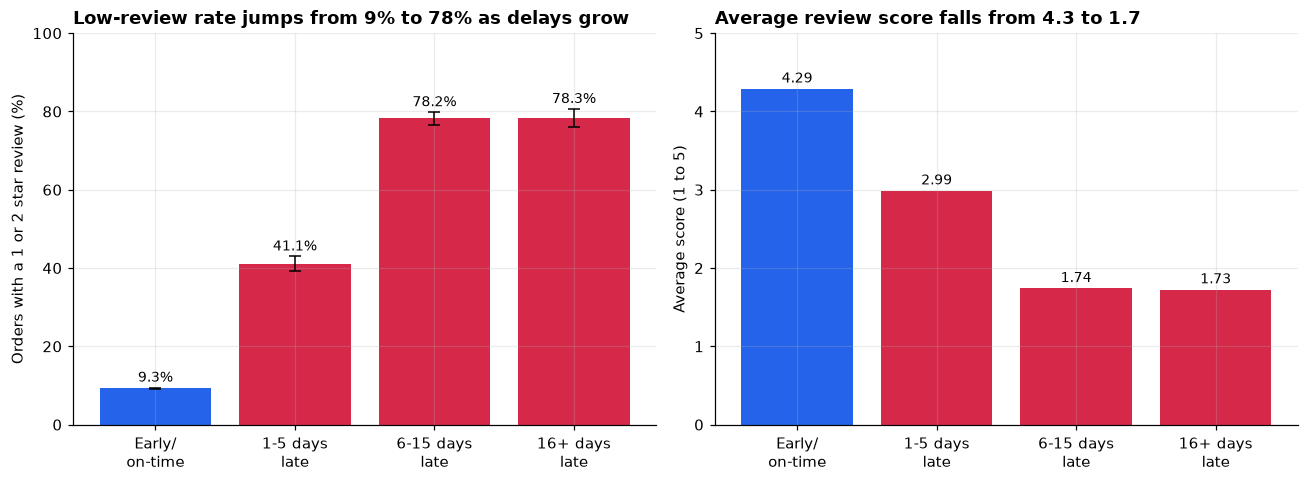

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
colors = [ONTIME, LATE, LATE, LATE]
labels = ["Early/\non-time", "1-5 days\nlate", "6-15 days\nlate", "16+ days\nlate"]

pcts = band_stats["low_review_pct"].to_numpy()
ps = pcts / 100
err = 1.96 * np.sqrt(ps * (1 - ps) / band_stats["reviewed"].to_numpy()) * 100
ax1.bar(labels, pcts, color=colors, yerr=err, capsize=4, error_kw={"lw": 1})
for i, v in enumerate(pcts):
    ax1.text(i, v + err[i] + 1.5, f"{v:.1f}%", ha="center", fontsize=9)
ax1.set_ylim(0, 100)
ax1.set_title("Low-review rate jumps from 9% to 78% as delays grow")
ax1.set_ylabel("Orders with a 1 or 2 star review (%)")

scores = band_stats["avg_score"].to_numpy()
ax2.bar(labels, scores, color=colors)
for i, v in enumerate(scores):
    ax2.text(i, v + 0.08, f"{v:.2f}", ha="center", fontsize=9)
ax2.set_ylim(0, 5)
ax2.set_title("Average review score falls from 4.3 to 1.7")
ax2.set_ylabel("Average score (1 to 5)")
plt.tight_layout()
plt.show()

Every late band has a higher low-review rate than on-time orders, and the confidence intervals do not overlap. Most of the increase happens in the first 5 days.

## 4. Logistic regression
Does late delivery still relate to low reviews after allowing for freight, order value and category? Categories with fewer than 200 orders are grouped as `other_categories`. Results are odds ratios (above 1 means higher odds of a low review).

In [24]:
df_model = df_fact.dropna(subset=["review_score"]).copy()
df_model["is_low_review"] = (df_model["review_score"] <= 2).astype(int)
df_model["category"] = df_model["category"].fillna("Unknown")

cat_counts = df_model["category"].value_counts()
rare = cat_counts[cat_counts < 200].index
df_model.loc[df_model["category"].isin(rare), "category"] = "other_categories"
reference = df_model["category"].value_counts().idxmax()

df_model["freight_per10"] = df_model["total_freight"] / 10
df_model["gmv_per100"] = df_model["total_gmv"] / 100

dummies = pd.get_dummies(df_model["category"], prefix="cat").drop(columns=f"cat_{reference}")
X = pd.concat([df_model[["is_late", "freight_per10", "gmv_per100"]], dummies], axis=1).astype(float)
X = sm.add_constant(X)
y = df_model["is_low_review"]

print(f"Orders in the model: {len(df_model):,} (reviewed orders only)")
print(f"Categories kept: {df_model['category'].nunique()} (reference: {reference}); grouped as other: {len(rare)}")

model = sm.Logit(y, X).fit(disp=0, maxiter=200)
print(f"Converged: {model.mle_retvals['converged']}   Pseudo R-squared: {model.prsquared:.3f}")

Orders in the model: 95,824 (reviewed orders only)
Categories kept: 44 (reference: BED_BATH_TABLE); grouped as other: 31
Converged: True   Pseudo R-squared: 0.144


In [25]:
or_table = pd.DataFrame({
    "odds_ratio": np.exp(model.params),
    "ci_low": np.exp(model.conf_int()[0]),
    "ci_high": np.exp(model.conf_int()[1]),
    "p_value": model.pvalues,
})
main = or_table.loc[["is_late", "freight_per10", "gmv_per100"]].copy()
main.index = ["Late delivery (yes vs no)", "Freight (per 10 units)", "Order GMV (per 100 units)"]
display(main.round(3))

crude = sm.Logit(y, sm.add_constant(df_model[["is_late"]].astype(float))).fit(disp=0)
crude_or = float(np.exp(crude.params["is_late"]))
adj_or = float(or_table.loc["is_late", "odds_ratio"])
print(f"Late delivery odds ratio: crude {crude_or:.2f}, adjusted {adj_or:.2f}")

cats = or_table[or_table.index.str.startswith("cat_")].sort_values("odds_ratio", ascending=False)
print(f"\nTop 5 categories by odds of a low review (compared with '{reference}'):")
display(cats.head(5).round(3))

,odds_ratio,ci_low,ci_high,p_value
Late delivery (yes vs no),16.409,15.513,17.356,0.00
Freight (per 10 units),1.096,1.085,1.106,0.00
Order GMV (per 100 units),1.008,0.999,1.018,0.09


Late delivery odds ratio: crude 16.24, adjusted 16.41

Top 5 categories by odds of a low review (compared with 'BED_BATH_TABLE'):


,odds_ratio,ci_low,ci_high,p_value
cat_AUDIO,1.347,0.999,1.816,0.051
cat_FIXED_TELEPHONY,1.223,0.826,1.811,0.316
cat_OFFICE_FURNITURE,1.112,0.943,1.312,0.206
cat_UNKNOWN,1.098,0.928,1.300,0.275
cat_HOME_CONFORT,1.056,0.783,1.424,0.721


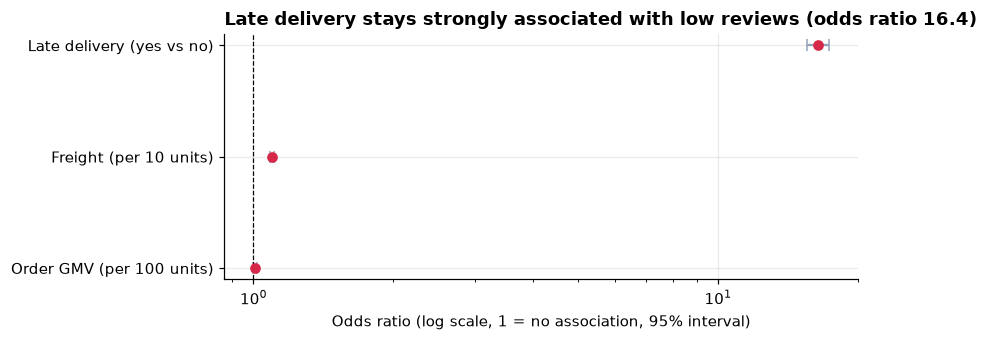

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.2))
vals = main["odds_ratio"].to_numpy()
errs = [vals - main["ci_low"].to_numpy(), main["ci_high"].to_numpy() - vals]
ax.errorbar(vals, range(len(vals)), xerr=errs, fmt="o", color=LATE, ecolor=GREY, capsize=4)
ax.axvline(1, color="black", lw=0.8, ls="--")
ax.set_yticks(range(len(vals)))
ax.set_yticklabels(main.index)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("Odds ratio (log scale, 1 = no association, 95% interval)")
ax.set_title(f"Late delivery stays strongly associated with low reviews (odds ratio {adj_or:.1f})")
plt.tight_layout()
plt.show()

In [27]:
print("Interpretation (association, not cause):")
print(f"- After allowing for freight, order value and category, late orders have about {adj_or:.1f} times the odds of a low review "
      f"(crude, before adjusting: {crude_or:.1f}).")
print(f"- Freight and order value have odds ratios close to 1 per unit; see the table for their direction.")
print("- The model describes this period and this marketplace only. It is not a forecast and not a causal estimate.")

Interpretation (association, not cause):
- After allowing for freight, order value and category, late orders have about 16.4 times the odds of a low review (crude, before adjusting: 16.2).
- Freight and order value have odds ratios close to 1 per unit; see the table for their direction.
- The model describes this period and this marketplace only. It is not a forecast and not a causal estimate.


After the controls, late orders have about 16 times the odds of a low review. Freight and order value matter much less. This is an association. Product quality and seller communication are not in the data.

## 5. Hypothetical scenarios
If the late rate falls by 1, 2, 3, 5 or 10 points, how many orders shift to on-time and how much GMV is associated? Shifted orders carry the average GMV of a late order. This is exposure, not recovered revenue. A 10-point fall is more than the whole late rate (6.77%), so it is capped at all late orders.

In [28]:
delivered = len(df_orders)
late_orders = int(df_orders["is_late"].sum())
late_rate_now = late_orders / delivered * 100
avg_late_gmv = df_orders.loc[df_orders["is_late"] == 1, "total_gmv"].sum() / late_orders

rows = []
for pts in [1, 2, 3, 5, 10]:
    wanted = delivered * pts / 100
    shifted = min(late_orders, wanted)
    rows.append({
        "late_rate_fall_points": pts,
        "orders_shifted_to_on_time": round(shifted),
        "share_of_late_orders_pct": round(shifted / late_orders * 100, 1),
        "late_rate_after_pct": round((late_orders - shifted) / delivered * 100, 2),
        "gmv_associated_hypothetical": round(shifted * avg_late_gmv, 2),
        "capped_at_all_late_orders": wanted > late_orders,
    })
scenarios = pd.DataFrame(rows)

print(f"Delivered orders {delivered:,} | late orders {late_orders:,} | late rate now {late_rate_now:.2f}% | average GMV of a late order {avg_late_gmv:,.2f}")
display(scenarios)

# cross-check with the SQL scenario results (1 point: 965 orders and 145,564.92; 5 points: 4,824 orders and 727,824.61)
s1_row = scenarios.set_index("late_rate_fall_points").loc[1]
s5_row = scenarios.set_index("late_rate_fall_points").loc[5]
assert abs(s1_row["orders_shifted_to_on_time"] - 965) <= 1 and abs(s1_row["gmv_associated_hypothetical"] - 145564.92) < 5, "1-point scenario differs from SQL"
assert abs(s5_row["orders_shifted_to_on_time"] - 4824) <= 1 and abs(s5_row["gmv_associated_hypothetical"] - 727824.61) < 5, "5-point scenario differs from SQL"
print("Cross-check with the SQL scenario table (and the Power BI slicer): PASS")

Delivered orders 96,470 | late orders 6,534 | late rate now 6.77% | average GMV of a late order 150.89


,late_rate_fall_points,orders_shifted_to_on_time,share_of_late_orders_pct,late_rate_after_pct,gmv_associated_hypothetical,capped_at_all_late_orders
0,1,965,14.8,5.77,145564.92,False
1,2,1929,29.5,4.77,291129.85,False
2,3,2894,44.3,3.77,436694.77,False
3,5,4824,73.8,1.77,727824.62,False
4,10,6534,100.0,0.00,985924.34,True


Cross-check with the SQL scenario table (and the Power BI slicer): PASS


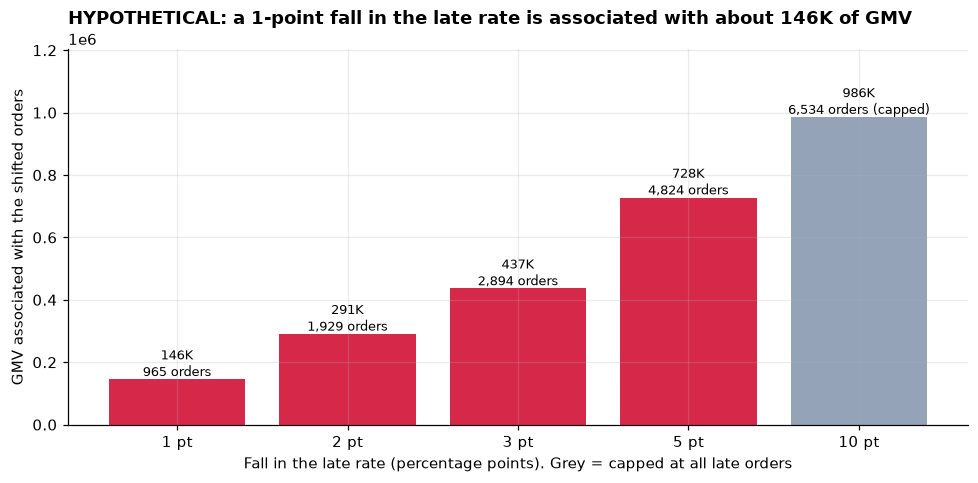

In [29]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [GREY if c else LATE for c in scenarios["capped_at_all_late_orders"]]
bars = ax.bar([f"{p} pt" for p in scenarios["late_rate_fall_points"]], scenarios["gmv_associated_hypothetical"], color=colors)
for b, (_, r) in zip(bars, scenarios.iterrows()):
    note = " (capped)" if r["capped_at_all_late_orders"] else ""
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 10000,
            f"{r['gmv_associated_hypothetical']/1000:,.0f}K\n{int(r['orders_shifted_to_on_time']):,} orders{note}", ha="center", fontsize=8.5)
ax.set_ylim(0, scenarios["gmv_associated_hypothetical"].max() * 1.22)
ax.set_title(f"HYPOTHETICAL: a 1-point fall in the late rate is associated with about {s1_row['gmv_associated_hypothetical']/1000:,.0f}K of GMV")
ax.set_xlabel("Fall in the late rate (percentage points). Grey = capped at all late orders")
ax.set_ylabel("GMV associated with the shifted orders")
plt.tight_layout()
plt.show()

A 1-point fall shifts 965 orders (about 145,565 of GMV). A 3-point fall shifts 2,894 orders (436,695). A 5-point fall (4,824 orders, 727,825) removes about 74% of late orders, so treat it as an upper bound.

## Summary

| Finding | Evidence | Action | Estimated impact (hypothetical) |
|---|---|---|---|
| Carrier transit is where late orders lose the most time | 27.87 days (late) against 7.93 (on-time) | Review carriers, starting with MA, CE, BA, RJ and PA | 1-point fall in late rate: about 965 orders, 145K GMV |
| Late delivery is associated with low reviews, mostly in the first 5 days | 9.28%, 41.15% and about 78% low reviews by band | Contact customers once an order passes its estimated date | 3,764 orders are 6+ days late with about 78% low reviews |
| A third of eligible sellers account for 80% of late orders | 252 of 804 sellers. Late rate 7.88% against 4.18% | Coach the top group, highest late rate first | About 2,160 fewer late orders if they matched the rest |
| About 1.0M of GMV sits in late orders | 985,924 late GMV, 619,012 also low-rated | Protect this exposure | See scenarios above |

Seller results use order-seller level, so totals differ slightly from order level (6,547 against 6,534 late). The data is Brazil 2016 to 2018, so treat the findings as a method, not current benchmarks.